In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"

# elif "augustiner" in hostname: 
#     DATA_DIR = "/home/franzihe/Data/"
#     FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)
# sys.path.append(os.path.join(UTILS_DIR, 'pymascdb'))
os.chdir(os.path.join(UTILS_DIR, 'pymascdb'))

# # make figure directory to put in reflectivity processed data
# try:
#     new_dir = pathlib.Path(FIG_DIR)
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

mimi.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
from imports_mascdb import (masc, np, pd, cm, xr, glob, set_context, plt, mdates, time, datetime, set_context, sns)

import functions_mascdb as fct

In [4]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [5]:
# reload imports
%load_ext autoreload
%autoreload 2

In [6]:
masc_in = os.path.join(INPUT_DATA_DIR, 'MASC_DB')
### Create MASC_DB instance 
mascdb = masc.MASC_DB(dir_path=masc_in)

In [7]:
campaign23 = mascdb.select_campaign('Norway-2023')


In [8]:
df = campaign23.triplet
df.set_index('datetime', inplace=True)
df.index = df.index.rename('time')

In [9]:
df.loc[df['snowflake_class_name'] == 'small_particle', 'snowflake_class_name'] = 'pristine'
df.loc[df['snowflake_class_name'] == 'planar_crystal', 'snowflake_class_name'] = 'pristine'
df.loc[df['snowflake_class_name'] == 'columnar_crystal', 'snowflake_class_name'] = 'pristine'
df.loc[df['snowflake_class_name'] == 'columnar_planar_combination', 'snowflake_class_name'] = 'pristine'

In [ ]:
df['fallspeed'][df['fallspeed'] > 7.] = np.nan

In [11]:
df['fallspeed'][df['fallspeed'] <= 0.2] = np.nan

In [12]:
df_only = dict()

In [13]:
df_only['aggregate'] = df[df['snowflake_class_name'] == 'aggregate']
df_only['graupel'] = df[df['snowflake_class_name'] == 'graupel']
df_only['pristine'] = df[df['snowflake_class_name'] == 'pristine']

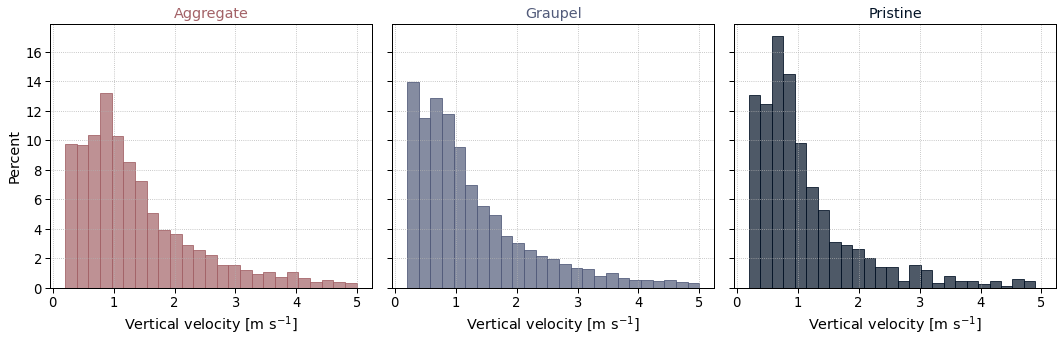

In [34]:
custom_colors = {key: fct.custom_colors[key] for key in ['aggregate', 'graupel', 'pristine']}

fig, axsm = plt.subplots(1, 3, figsize=(15, 5, ), sharex=True, sharey=True)
axs = axsm.flatten()


for ax, (class_name, color) in zip(axs, custom_colors.items()):
    sns.histplot(df_only[class_name]['fallspeed'], bins=25, stat='percent', ax=ax, color=color, alpha=0.7, edgecolor=color)
    # sns.histplot(df_only['graupel']['fallspeed'], bins=25, stat='percent', ax=ax, color=custom_colors['aggregate'], alpha=0., edgecolor=custom_colors['aggregate'])
    # sns.histplot(df_only[class_name]['fallspeed'], stat='percent', ax=ax, cumulative=True, element='poly', fill=False, color=color)
    # sns.histplot(df_only['aggregate']['fallspeed'], stat='percent', ax=ax, cumulative=False, element='poly', fill=False, color=custom_colors['aggregate'], label='aggregate')
    # sns.histplot(df_only['graupel']['fallspeed'], stat='percent', ax=ax, cumulative=False, element='poly', fill=False, color=custom_colors['graupel'], label='graupel')
    # sns.histplot(df_only['pristine']['fallspeed'], stat='percent', ax=ax, cumulative=False, element='poly', fill=False, color=custom_colors['pristine'], label='pristine')

    ax.set(xlabel = "Vertical velocity [m s$^{-1}$]")
    ax.grid(True, ls=':')
    ax.set_title(f"{class_name}".title(), color=color)


# plt.legend()
plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR, 'fallspeed', 'aggregate_graupel_pristine_Norway-2023.png'), format='png', bbox_inches='tight', dpi=300, transparent=True,)

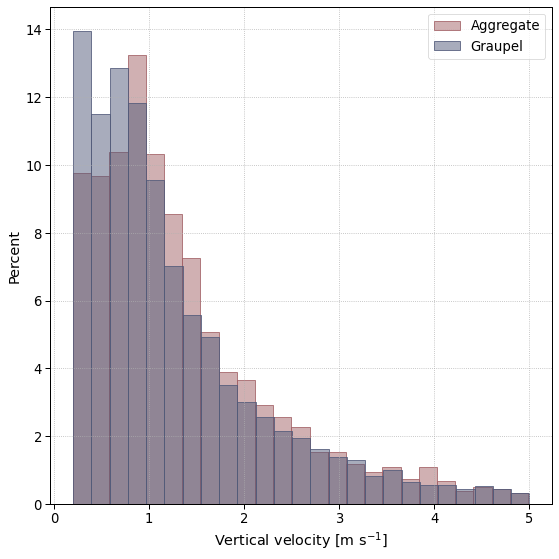

In [35]:
custom_colors = {key: fct.custom_colors[key] for key in ['aggregate', 'graupel',]}
fig, axs = plt.subplots(1, 1, figsize=(8, 8, ), sharex=True, sharey=True)
# axs = axsm.flatten()

for (class_name, color) in  custom_colors.items():
    sns.histplot(df_only[class_name]['fallspeed'], bins=25, stat='percent', ax=axs, color=color, alpha=0.5, edgecolor=color, label=f"{class_name}".title())


axs.set(xlabel = "Vertical velocity [m s$^{-1}$]")
axs.grid(True, ls=':')
    # ax.set_title(f"{class_name}".title(), color=color)


plt.legend()
plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR, 'fallspeed', 'aggregate_graupel_Norway-2023.png'), format='png', bbox_inches='tight', dpi=300) #transparent=True,